<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/Pr%C3%A1ctica_Validaci%C3%B3n%2C_evaluaci%C3%B3n_y_selecci%C3%B3n_271758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica: Validación, evaluación y selección**

Kevin Angel Quiñonez Dominguez

271758


## **1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos**

Declarar las bibliotecas necesarias para este proyecto
Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features. Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from google.colab import drive

drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Unidad03/TCGA_InfoWithGrade.csv')
display(df.head())

Mounted at /content/drive


,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,0,0,51.30,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,0,0,38.72,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,35.17,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,32.78,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0,31.51,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## **2. 📊 Análisis exploratorio de datos (EDA)**


Realiza un análisis inicial de los datos antes de modelar:

* Describir forma y estructura (shape, describe(), info()).

* Mostrar la distribución de clases (y.value_counts()).

Visualizar:

* Histograma de al menos 3 variables numéricas.

* Boxplots o violin plots por clase si es computacionalmente viable.

* Mapa de calor de correlaciones entre variables.

🧠 Reflexiona:

* ¿Existen clases desbalanceadas?

* ¿Qué atributos parecen más informativos?



In [2]:
print("--- Shape ---")
display(df.shape)
print("--- Describe ---")
display(df.describe())
print("--- Info ---")
display(df.info())
print("--- Value counts ---")
display(df['Grade'].value_counts())




--- Shape ---


(839, 24)

--- Describe ---


,Grade,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
count,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,...,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
mean,0.419547,0.418355,50.935411,0.107271,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,...,0.053635,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222
std,0.493779,0.493583,15.702339,0.369392,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,...,0.225431,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889
min,0.000000,0.000000,14.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,38.055000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,51.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,1.000000,62.800000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,89.290000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grade             839 non-null    int64  
 1   Gender            839 non-null    int64  
 2   Age_at_diagnosis  839 non-null    float64
 3   Race              839 non-null    int64  
 4   IDH1              839 non-null    int64  
 5   TP53              839 non-null    int64  
 6   ATRX              839 non-null    int64  
 7   PTEN              839 non-null    int64  
 8   EGFR              839 non-null    int64  
 9   CIC               839 non-null    int64  
 10  MUC16             839 non-null    int64  
 11  PIK3CA            839 non-null    int64  
 12  NF1               839 non-null    int64  
 13  PIK3R1            839 non-null    int64  
 14  FUBP1             839 non-null    int64  
 15  RB1               839 non-null    int64  
 16  NOTCH1            839 non-null 

None

--- Value counts ---


,count
Grade,
0,487
1,352


/tmp/ipykernel_1402/2564336648.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Grade', ax=axes[1], palette='Set2')
/tmp/ipykernel_1402/2564336648.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='IDH1', ax=axes[2], palette='Set1')


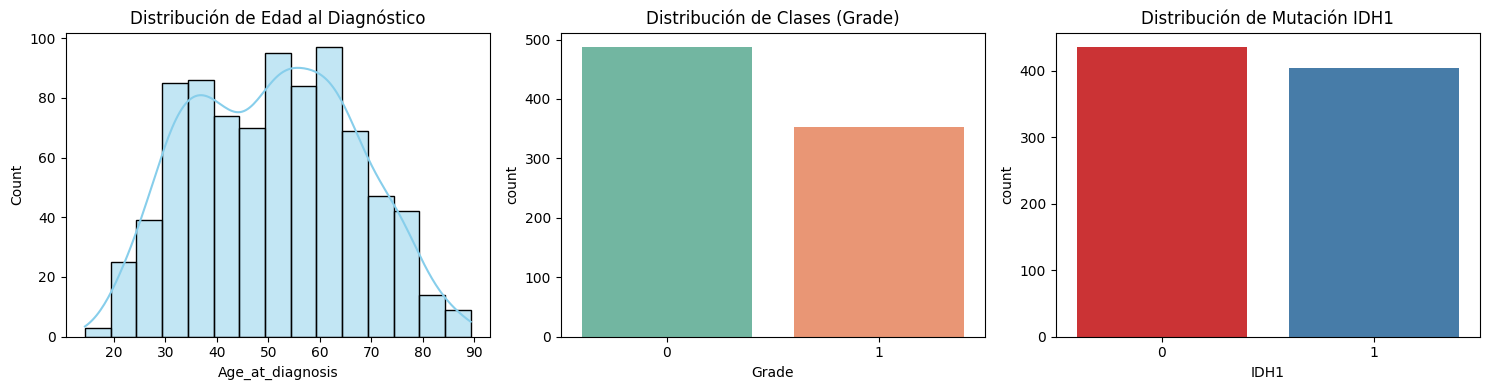

/tmp/ipykernel_1402/2564336648.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


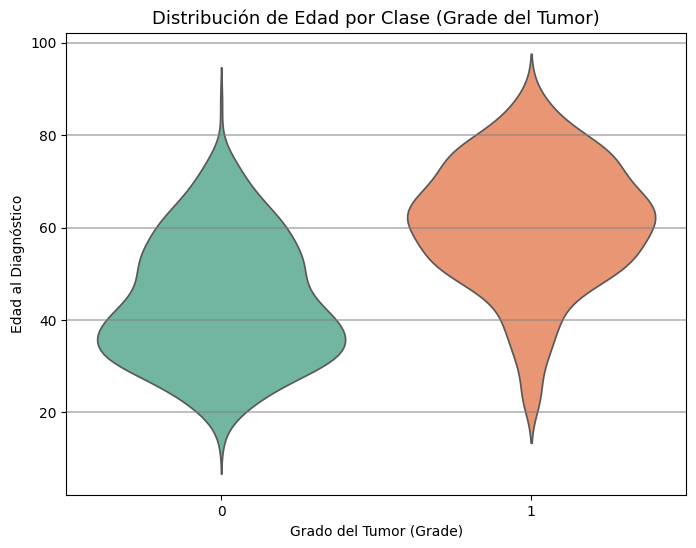

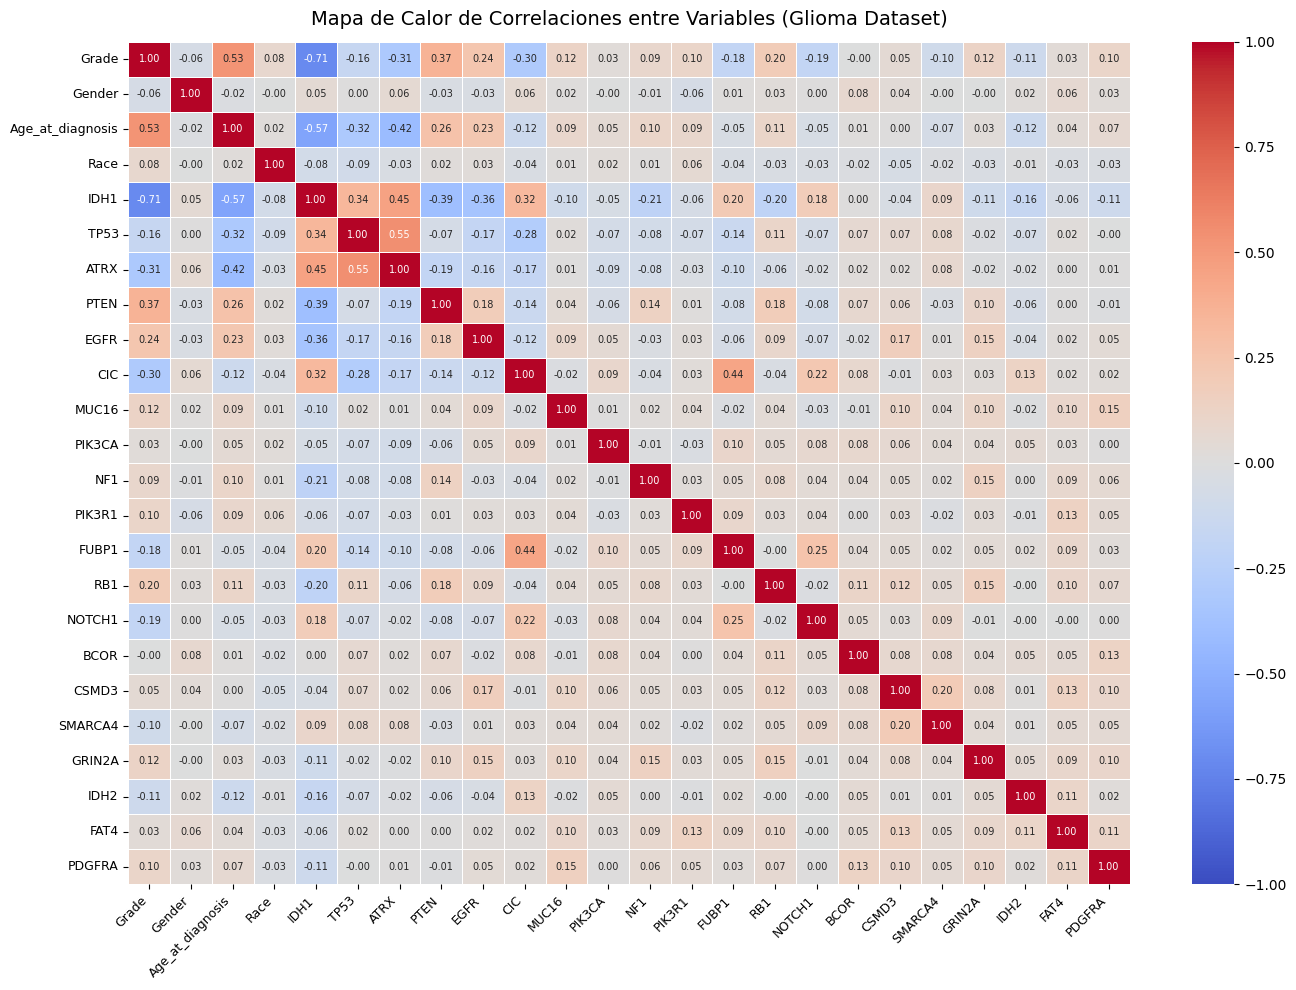

In [3]:
# Histogramas 3 variables
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['Age_at_diagnosis'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Edad al Diagnóstico')

sns.countplot(data=df, x='Grade', ax=axes[1], palette='Set2')
axes[1].set_title('Distribución de Clases (Grade)')

sns.countplot(data=df, x='IDH1', ax=axes[2], palette='Set1')
axes[2].set_title('Distribución de Mutación IDH1')

plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))

sns.violinplot(
    data=df,
    x='Grade',
    y='Age_at_diagnosis',
    palette='Set2',
    inner=None  # <-- Quita las líneas internas
)

plt.title('Distribución de Edad por Clase (Grade del Tumor)', fontsize=13)
plt.xlabel('Grado del Tumor (Grade)')
plt.ylabel('Edad al Diagnóstico')

# Personalización de la cuadrícula para hacerla resaltar más
plt.grid(
    axis='y',
    linestyle='-',     # Línea sólida en lugar de punteada '--'
    linewidth=1.2,     # Mayor grosor
    color='gray',      # Color más visible
    alpha=0.6          # Mayor visibilidad/opacidad
)

plt.show()

# 1. Calcular la matriz de correlación (Pearson)
corr_matrix = df.corr()

# 2. Configurar el tamaño del lienzo
plt.figure(figsize=(14, 10))

# 3. Graficar el mapa de calor
sns.heatmap(
    corr_matrix,
    annot=True,          # Muestra el valor numérico de la correlación en cada celda
    fmt='.2f',           # Formato a 2 decimales
    cmap='coolwarm',     # Paleta de colores (rojo = positiva, azul = negativa)
    vmin=-1, vmax=1,     # Escala fija de -1 a 1
    linewidths=0.5,      # Separación entre celdas
    annot_kws={"size": 7} # Tamaño de la letra de los números dentro de la celda
)

plt.title('Mapa de Calor de Correlaciones entre Variables (Glioma Dataset)', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()




**¿Existen clases desbalanceadas?**

 No se consideran clases desbalanceadas.

Clase 0: 487 observaciones ($\approx 58.05\%$).   

Clase 1: 352 observaciones ($\approx 41.95\%$).   

Análisis: La proporción ronda un balance de $58/42$. En problemas de clasificación binaria, un desbalance real que requiera técnicas de resoplado (como SMOTE o ajuste de pesos de clase) ocurre habitualmente a partir de relaciones $80/20$ o más extremas. Por lo tanto, el conjunto de datos está suficientemente balanceado para entrenar directamente modelos como árboles de decisión sin introducir un sesgo severo hacia la clase mayoritaria.

**¿Qué atributos parecen más informativos?**

Al observar tanto el mapa de calor de correlaciones como el violin plot, los atributos más potentes para predecir el grado del tumor (Grade) son:

* IDH1 (Correlación: $-0.71$): Es el atributo más informativo de todo el dataset. Presenta una fuerte correlación negativa con Grade. La mutación en el gen IDH1 está fuertemente presente en tumores de bajo grado (Grade = 0) y suele estar ausente en gliomas de alto grado (Grade = 1).   

* Age_at_diagnosis (Correlación: $+0.53$): Es la variable continua más relevante. En el violin plot se observa con claridad que la mediana de edad para tumores Grade = 1 se sitúa alrededor de los 60-65 años, mientras que para Grade = 0 se concentra entre los 35-40 años.   

* PTEN (Correlación: $+0.37$) y ATRX (Correlación: $-0.31$): Tienen asociaciones lineales moderadas pero estadísticamente útiles para complementar las divisiones del árbol de decisión.   

* CIC (Correlación: $-0.30$) y EGFR (Correlación: $+0.24$): Aportan información secundaria relevante para la diferenciación de subgrupos de tumor.   

Atributos poco informativos: Variables como Gender (correlación $-0.06$) o Race (correlación $+0.08$) muestran una relación prácticamente nula con el grado de severidad del tumor.   

# **3. Gráfica de Errores en Entrenamiento y Prueba**

En este ejercicio vas a entrenar un árbol de decisión con diferentes profundidas. Asimismo, en gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10
* Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None
* Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3
* Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades
* Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7
* Muestra una gráfica para los distintos resultados  cuando se usa F1 Macro

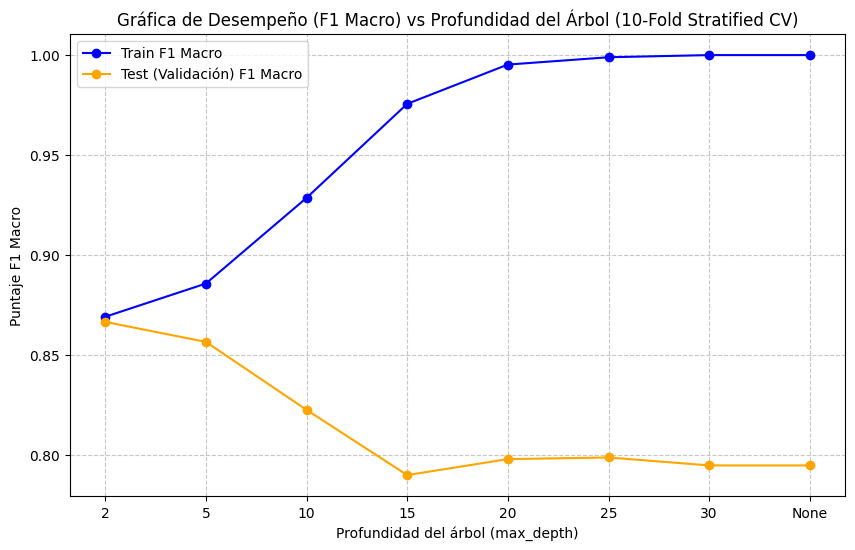

In [4]:
# 1. Definir X e y
X = df.drop(columns=['Grade'])
y = df['Grade']

# 2. Configurar StratifiedKFold con 10 particiones y random_state=3
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

# 3. Lista de profundidades a evaluar
depths = [2, 5, 10, 15, 20, 25, 30, None]

train_f1_scores = []
test_f1_scores = []

# 4. Iterar sobre cada profundidad
for depth in depths:
    # Modelo con random_state=7
    model = DecisionTreeClassifier(max_depth=depth, random_state=7)

    # Evaluación cruzada para train y test usando scoring='f1_macro'
    scores = cross_validate(
        model, X, y,
        cv=skf,
        scoring='f1_macro',
        return_train_score=True
    )

    # Guardar los promedios de F1 Macro
    train_f1_scores.append(scores['train_score'].mean())
    test_f1_scores.append(scores['test_score'].mean())

# Convertir 'None' a String solo para mostrarlo correctamente en el eje X de la gráfica
depth_labels = [str(d) for d in depths]

# 5. Visualizar la gráfica de F1 Macro
plt.figure(figsize=(10, 6))
plt.plot(depth_labels, train_f1_scores, marker='o', label='Train F1 Macro', color='blue')
plt.plot(depth_labels, test_f1_scores, marker='o', label='Test (Validación) F1 Macro', color='orange')

plt.xlabel("Profundidad del árbol (max_depth)")
plt.ylabel("Puntaje F1 Macro")
plt.title("Gráfica de Desempeño (F1 Macro) vs Profundidad del Árbol (10-Fold Stratified CV)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# **4. Optimización de hiperparámetros con RandomizedSearchCV**

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
* Criterion = gini ,entropy
* max_depth: de 5 a 50 con incrementos de 1
* min_samples_split: de 2 a 20 con incrementos de 1
* Usa el árbol de decisión
* StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
* n_iter = 5 (combinaciones aleatorias a buscar)
* n_jobs = -1 para acelerar cómputo
* Métrica de evaluación: f1 Macro

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [5]:


# 1. Definir el espacio de búsqueda aleatorio (param_distributions)
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),            # De 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))     # De 2 a 20 con incrementos de 1
}

# 2. Configurar StratifiedKFold = 10
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Instanciar el modelo base de Árbol de Decisión
tree_clf = DecisionTreeClassifier(random_state=42)

# 4. Configurar RandomizedSearchCV con todos los parámetros especificados
random_search = RandomizedSearchCV(
    estimator=tree_clf,
    param_distributions=param_dist,
    n_iter=5,                    # Combinaciones aleatorias a probar
    scoring='f1_macro',          # Métrica de evaluación
    cv=cv_stratified,            # Validación cruzada estratificada con 10 folds
    n_jobs=-1,                   # Usar todos los núcleos disponibles para acelerar cómputo
    random_state=42
)

# 5. Entrenar la búsqueda con todo el dataset (sin partición previa)
random_search.fit(X, y)

# 6. Imprimir los resultados requeridos
print("--- Resultados de RandomizedSearchCV ---")
print("Mejores hiperparámetros encontrados:")
print(random_search.best_params_)

print(f"\nMejor puntaje (Best F1 Macro Score): {random_search.best_score_:.4f}")

--- Resultados de RandomizedSearchCV ---
Mejores hiperparámetros encontrados:
{'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}

Mejor puntaje (Best F1 Macro Score): 0.8318


# **5. Optimización de hiperparámetros con GridSearchCV**

Define el espacio de búsqueda  para los siguientes hiperpárametros:
* Criterion = gini ,entropy
* max_depth: de 5 a 50 con incrementos de 1
* min_samples_split: de 2 a 20 con incrementos de 1
* Usa el árbol de decisión
* StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
* n_jobs = -1 para acelerar cómputo
* Métrica de evaluación: f1 Macro

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [6]:
# 1. Definir la malla de parámetros (param_grid)
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),            # De 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))     # De 2 a 20 con incrementos de 1
}

# 2. Configurar StratifiedKFold = 10
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Instanciar el modelo base de Árbol de Decisión
tree_clf = DecisionTreeClassifier(random_state=42)

# 4. Configurar GridSearchCV
# Nota: Se usa param_grid en lugar de param_distributions y se elimina random_state
grid_search = GridSearchCV(
    estimator=tree_clf,
    param_grid=param_grid,
    scoring='f1_macro',          # Métrica de evaluación
    cv=cv_stratified,            # Validación cruzada estratificada con 10 folds
    n_jobs=-1                    # Usar todos los núcleos disponibles
)

# 5. Entrenar la búsqueda exhaustiva con todo el dataset (sin partición previa)
grid_search.fit(X, y)

# 6. Imprimir los resultados requeridos
print("--- Resultados de GridSearchCV ---")
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)

print(f"\nMejor puntaje (Best F1 Macro Score): {grid_search.best_score_:.4f}")

--- Resultados de GridSearchCV ---
Mejores hiperparámetros encontrados:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 12}

Mejor puntaje (Best F1 Macro Score): 0.8641


# **6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy**

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
* Criterion = gini ,entropy
* max_depth: de 5 a 50 con incrementos de 1
* min_samples_split: de 2 a 20 con incrementos de 1
* Usa el árbol de decisión
* StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
* n_iter = 5 (combinaciones aleatorias a buscar)
* n_jobs = -1 para acelerar cómputo
* Métrica de evaluación: accuracy

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [7]:
# 1. Definir el espacio de búsqueda aleatorio (param_distributions)
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),            # De 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))     # De 2 a 20 con incrementos de 1
}

# 2. Configurar StratifiedKFold = 10
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Instanciar el modelo base de Árbol de Decisión
tree_clf = DecisionTreeClassifier(random_state=42)

# 4. Configurar RandomizedSearchCV con métrica 'accuracy'
random_search_acc = RandomizedSearchCV(
    estimator=tree_clf,
    param_distributions=param_dist,
    n_iter=5,                    # Combinaciones aleatorias a buscar
    scoring='accuracy',          # Métrica de evaluación solicitada
    cv=cv_stratified,            # Validación cruzada estratificada de 10 folds
    n_jobs=-1,                   # Usar todos los núcleos disponibles
    random_state=42
)

# 5. Entrenar la búsqueda con todo el dataset (sin partición previa)
random_search_acc.fit(X, y)

# 6. Imprimir los resultados requeridos
print("--- Resultados de RandomizedSearchCV (Accuracy) ---")
print("Mejores hiperparámetros encontrados:")
print(random_search_acc.best_params_)

print(f"\nMejor puntaje (Best Accuracy Score): {random_search_acc.best_score_:.4f}")

--- Resultados de RandomizedSearchCV (Accuracy) ---
Mejores hiperparámetros encontrados:
{'min_samples_split': 11, 'max_depth': 18, 'criterion': 'entropy'}

Mejor puntaje (Best Accuracy Score): 0.8367


# **7. Optimización de hiperparámetros con GridSearchCV: accuracy**

Define el espacio de búsqueda  para los siguientes hiperpárametros:
* Criterion = gini ,entropy
* max_depth: de 5 a 50 con incrementos de 1
* min_samples_split: de 2 a 20 con incrementos de 1
* Usa el árbol de decisión
* StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
* n_jobs = -1 para acelerar cómputo
* Métrica de evaluación: Accuracy

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [8]:

# 1. Definir la malla de parámetros (param_grid)
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),            # De 5 a 50 con incrementos de 1
    'min_samples_split': list(range(2, 21))     # De 2 a 20 con incrementos de 1
}

# 2. Configurar StratifiedKFold = 10
cv_stratified = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 3. Instanciar el modelo base de Árbol de Decisión
tree_clf = DecisionTreeClassifier(random_state=42)

# 4. Configurar GridSearchCV con métrica 'accuracy'
grid_search_acc = GridSearchCV(
    estimator=tree_clf,
    param_grid=param_grid,
    scoring='accuracy',          # Métrica de evaluación solicitada
    cv=cv_stratified,            # Validación cruzada estratificada con 10 folds
    n_jobs=-1                    # Usar todos los núcleos disponibles
)

# 5. Entrenar la búsqueda exhaustiva con todo el dataset
grid_search_acc.fit(X, y)

# 6. Imprimir los resultados requeridos
print("--- Resultados de GridSearchCV (Accuracy) ---")
print("Mejores hiperparámetros encontrados:")
print(grid_search_acc.best_params_) #[cite: 28]

print(f"\nMejor puntaje (Best Accuracy Score): {grid_search_acc.best_score_:.4f}") #[cite: 28]

--- Resultados de GridSearchCV (Accuracy) ---
Mejores hiperparámetros encontrados:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 12}

Mejor puntaje (Best Accuracy Score): 0.8653


# **8.Actividad de reflexión y análisis**

**¿Cuál método encontró mejores hiperparámetros?**
* GridSearchCV encontro los mejores hiperparámetros.  Logró un F1 Macro de $0.8641$ frente a $0.8318$ de RandomizedSearchCV, y un Accuracy de $0.8653$ frente a $0.8367$ de RandomizedSearchCV. Además, identificó una estructura de árbol mucho más simple y menos propensa al sobreajuste (max_depth: 5 vs max_depth: 18).   

**¿Cuál fue más costoso computacionalmente?**

* GridSearchCV fue significativamente más costoso. Evaluó exhaustivamente la totalidad de las 1,748 combinaciones posibles multiplicadas por los 10 folds de validación cruzada ($17,480$ ajustes de modelos en total), tomando aproximadamente 2 minutos de procesamiento. En contraste, RandomizedSearchCV únicamente muestreó al azar 5 combinaciones ($50$ ajustes en total), completándose en escasos segundos.   

**¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?**

* Sí, fueron distintos. GridSearchCV explora minuciosamente todo el espacio de búsqueda, por lo que garantizó encontrar el óptimo global dentro del rango (max_depth: 5, min_samples_split: 12). RandomizedSearchCV, al estar limitado a solo $5$ iteraciones aleatorias (n_iter=5), no llegó a muestrear esa combinación óptima en particular, quedándose atrapado en una combinación subóptima pero aceptable (max_depth: 18).   

**¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?**

* Sí, también fueron distintos.Por la misma razón metodológica: RandomizedSearchCV utilizó la misma semilla aleatoria de muestreo (random_state=42), por lo que probó exactamente las mismas 5 combinaciones al azar que en F1 Macro. GridSearchCV, al revisar todas las celdas de la malla, identificó de nuevo que max_depth: 5 produce la mayor exactitud general ($86.53\%$).

**¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?**

Sí, dentro de cada método los hiperparámetros elegidos coinciden perfectamente entre ambas métricas.   GridSearchCV: Seleccionó {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 12} tanto para F1 Macro como para Accuracy.   

RandomizedSearchCV: Seleccionó {'criterion': 'entropy', 'max_depth': 18, 'min_samples_split': 11} en ambos casos.   

Esto sucede porque en este dataset de Glioma las clases están razonablemente bien balanceadas ($\approx 58/42$), por lo que optimizar la exactitud general (Accuracy) o el promedio armónico por clase (F1 Macro) orienta al árbol a realizar las mismas divisiones óptimas.